In [ ]:
# Satellite Image Analysis
# Project: Earth Observation with Python

import numpy as np
import matplotlib.pyplot as plt

print("Satellite Image Analysis project started!")
print("NumPy version:", np.__version__)

Satellite Image Analysis project started!
NumPy version: 2.1.3


In [ ]:
%pip install rasterio

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

print("Rasterio version:", rasterio.__version__)
print("All imports successful!")

Rasterio version: 1.5.2
All imports successful!


In [ ]:
%pip install -q pystac-client planetary-computer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.4 MB/s eta 0:00:00


In [ ]:
from pystac_client import Client
import planetary_computer

# Connect to the public satellite data catalogue
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

# Example area around Kanpur, India
kanpur_bbox = [80.2, 26.3, 80.5, 26.6]

# Search for relatively cloud-free Sentinel-2 imagery
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=kanpur_bbox,
    datetime="2025-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=10
)

items = list(search.items())

print("Images found:", len(items))

for item in items[:5]:
    print(
        "Date:", item.datetime.date(),
        "| Cloud cover:", item.properties.get("eo:cloud_cover"),
        "| ID:", item.id
    )

Images found: 10
Date: 2025-12-13 | Cloud cover: 4.559127 | ID: S2A_MSIL2A_20251213T052241_R062_T44RMQ_20251213T083109
Date: 2025-12-13 | Cloud cover: 3.691129 | ID: S2B_MSIL2A_20251213T051119_R019_T44RMQ_20251213T070912
Date: 2025-12-11 | Cloud cover: 0.007965 | ID: S2C_MSIL2A_20251211T052231_R062_T44RMQ_20251211T091614
Date: 2025-12-06 | Cloud cover: 0.001103 | ID: S2B_MSIL2A_20251206T052109_R062_T44RMQ_20251206T072603
Date: 2025-12-03 | Cloud cover: 1.77942 | ID: S2B_MSIL2A_20251203T051059_R019_T44RMQ_20251203T071459


In [ ]:
print("Runtime is working!")

print("Number of satellite images:", len(items))

# Show the details of the best available image
item = items[0]

print("Date:", item.datetime.date())
print("Cloud cover:", item.properties.get("eo:cloud_cover"), "%")
print("Available bands:", list(item.assets.keys()))

Runtime is working!


NameError: name 'items' is not defined

In [1]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

kanpur_bbox = [80.2, 26.3, 80.5, 26.6]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=kanpur_bbox,
    datetime="2025-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=10
)

items = list(search.items())

print("Images found:", len(items))
print("Selected image date:", items[0].datetime.date())
print("Cloud cover:", items[0].properties.get("eo:cloud_cover"))

ModuleNotFoundError: No module named 'pystac_client'

In [2]:
%pip install -q pystac-client planetary-computer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.4 MB/s eta 0:00:00


In [3]:
import pystac_client
import planetary_computer

print("pystac-client:", pystac_client.__version__)
print("Planetary Computer imported successfully!")

pystac-client: 0.9.1
Planetary Computer imported successfully!


In [4]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

kanpur_bbox = [80.2, 26.3, 80.5, 26.6]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=kanpur_bbox,
    datetime="2025-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=10
)

items = list(search.items())

print("Images found:", len(items))

if items:
    item = items[0]
    print("Selected date:", item.datetime.date())
    print("Cloud cover:", item.properties.get("eo:cloud_cover"), "%")
    print("Available bands:", list(item.assets.keys()))

Images found: 10
Selected date: 2025-12-13
Cloud cover: 4.559127 %
Available bands: ['AOT', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'SCL', 'WVP', 'visual', 'safe-manifest', 'granule-metadata', 'inspire-metadata', 'product-metadata', 'datastrip-metadata', 'tilejson', 'rendered_preview']


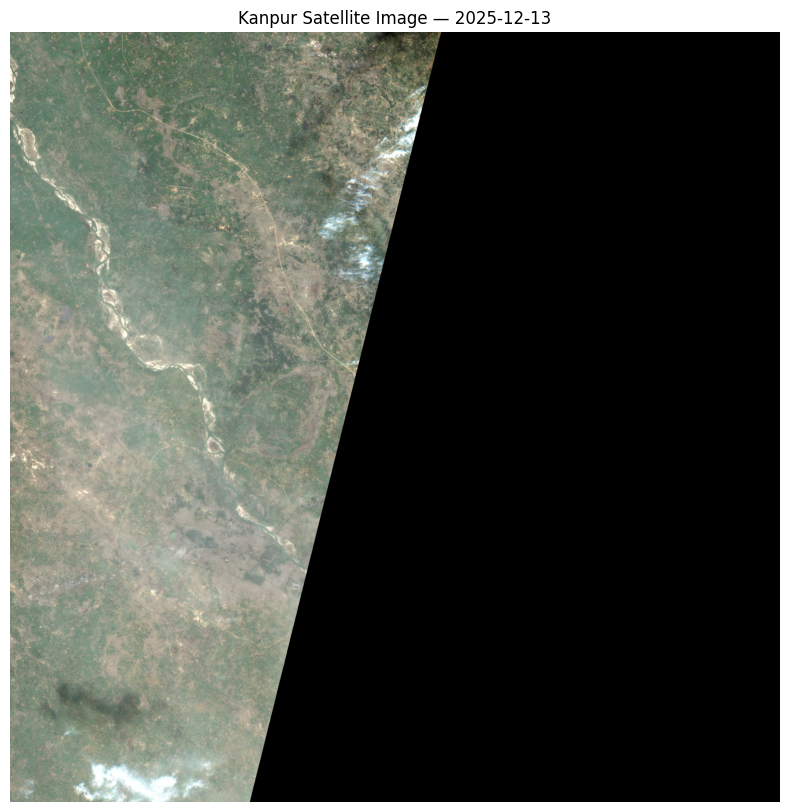

In [5]:
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import reshape_as_image

# Select the first satellite image
item = items[0]

# Open its rendered natural-colour image
image_url = item.assets["visual"].href

with rasterio.open(image_url) as src:
    image = src.read()
    image = reshape_as_image(image)

# Display the image
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.title(f"Kanpur Satellite Image — {item.datetime.date()}")
plt.axis("off")
plt.show()

In [7]:
# Inspect the satellite image bands

item = items[0]

for band in ["B02", "B03", "B04", "B08"]:
    asset = item.assets[band]
    print(f"{band}: {asset.title}")
    print("  Resolution:", asset.extra_fields.get("gsd", "Check metadata"))
    print()

B02: Band 2 - Blue - 10m
  Resolution: 10

B03: Band 3 - Green - 10m
  Resolution: 10

B04: Band 4 - Red - 10m
  Resolution: 10

B08: Band 8 - NIR - 10m
  Resolution: 10



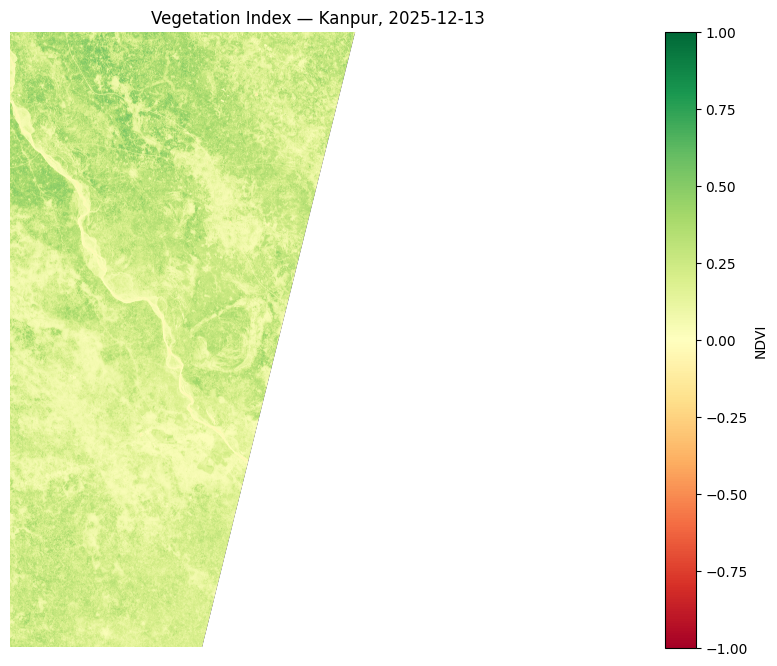

Minimum NDVI: -0.99929655
Maximum NDVI: 0.61596245
Mean NDVI: 0.2068726


In [8]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

item = items[0]

# Read Red band (B04)
with rasterio.open(item.assets["B04"].href) as src:
    red = src.read(1).astype("float32")
    red[red == 0] = np.nan

# Read Near-Infrared band (B08)
with rasterio.open(item.assets["B08"].href) as src:
    nir = src.read(1).astype("float32")
    nir[nir == 0] = np.nan

# Calculate NDVI
denominator = nir + red
ndvi = np.divide(
    nir - red,
    denominator,
    out=np.full_like(nir, np.nan),
    where=denominator != 0
)

# Display NDVI map
plt.figure(figsize=(10, 8))
plt.imshow(
    np.ma.masked_invalid(ndvi),
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
plt.colorbar(label="NDVI")
plt.title(f"Vegetation Index — Kanpur, {item.datetime.date()}")
plt.axis("off")
plt.show()

print("Minimum NDVI:", np.nanmin(ndvi))
print("Maximum NDVI:", np.nanmax(ndvi))
print("Mean NDVI:", np.nanmean(ndvi))

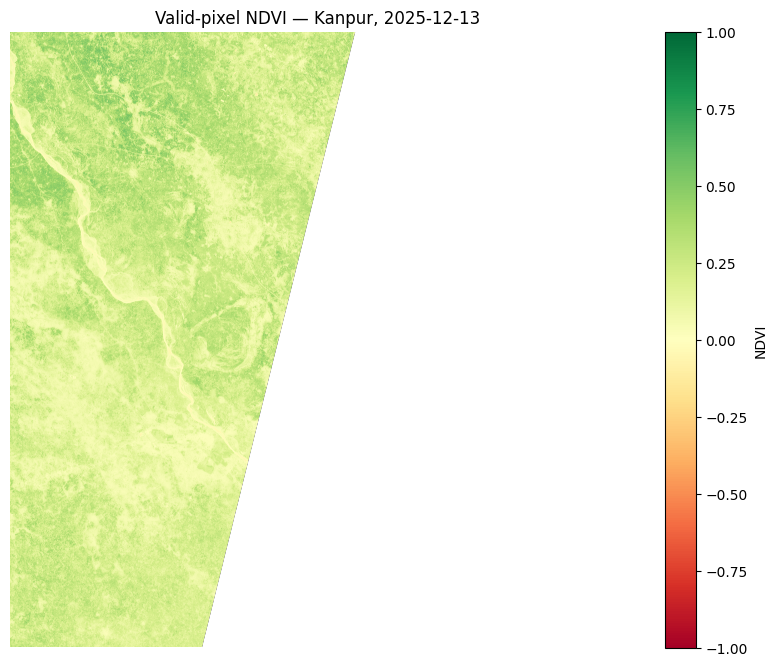

Valid pixels: 52515400
Minimum NDVI: -0.99929655
Maximum NDVI: 0.61596245
Mean NDVI: 0.2068726


In [9]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

item = items[0]

with rasterio.open(item.assets["B04"].href) as src:
    red = src.read(1).astype("float32")
    red_valid = src.read_masks(1) > 0

with rasterio.open(item.assets["B08"].href) as src:
    nir = src.read(1).astype("float32")
    nir_valid = src.read_masks(1) > 0

# Keep only pixels valid in both bands
valid = red_valid & nir_valid & (red > 0) & (nir > 0)

denominator = nir + red
ndvi = np.full(red.shape, np.nan, dtype="float32")

np.divide(
    nir - red,
    denominator,
    out=ndvi,
    where=valid & (denominator != 0)
)

plt.figure(figsize=(10, 8))
plt.imshow(np.ma.masked_invalid(ndvi), cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title(f"Valid-pixel NDVI — Kanpur, {item.datetime.date()}")
plt.axis("off")
plt.show()

print("Valid pixels:", np.count_nonzero(np.isfinite(ndvi)))
print("Minimum NDVI:", np.nanmin(ndvi))
print("Maximum NDVI:", np.nanmax(ndvi))
print("Mean NDVI:", np.nanmean(ndvi))

In [10]:
# Check all 10 candidate images
for i, candidate in enumerate(items):
    print(
        i,
        "| Date:", candidate.datetime.date(),
        "| Cloud:", round(candidate.properties.get("eo:cloud_cover", 100), 2),
        "| ID:", candidate.id
    )

0 | Date: 2025-12-13 | Cloud: 4.56 | ID: S2A_MSIL2A_20251213T052241_R062_T44RMQ_20251213T083109
1 | Date: 2025-12-13 | Cloud: 3.69 | ID: S2B_MSIL2A_20251213T051119_R019_T44RMQ_20251213T070912
2 | Date: 2025-12-11 | Cloud: 0.01 | ID: S2C_MSIL2A_20251211T052231_R062_T44RMQ_20251211T091614
3 | Date: 2025-12-06 | Cloud: 0.0 | ID: S2B_MSIL2A_20251206T052109_R062_T44RMQ_20251206T072603
4 | Date: 2025-12-03 | Cloud: 1.78 | ID: S2B_MSIL2A_20251203T051059_R019_T44RMQ_20251203T071459
5 | Date: 2025-12-01 | Cloud: 0.01 | ID: S2C_MSIL2A_20251201T052211_R062_T44RMQ_20251201T084410
6 | Date: 2025-12-01 | Cloud: 1.22 | ID: S2C_MSIL2A_20251201T052211_R062_T44RMQ_20251201T083613
7 | Date: 2025-11-30 | Cloud: 0.17 | ID: S2A_MSIL2A_20251130T051241_R019_T44RMQ_20251130T074610
8 | Date: 2025-11-28 | Cloud: 0.0 | ID: S2C_MSIL2A_20251128T051201_R019_T44RMQ_20251128T101117
9 | Date: 2025-11-26 | Cloud: 0.0 | ID: S2B_MSIL2A_20251126T052039_R062_T44RMQ_20251126T072608


In [11]:
from shapely.geometry import box, shape

# The area we want to study
target_area = box(*kanpur_bbox)

print("Checking scene coverage:\n")

for i, candidate in enumerate(items):
    footprint = shape(candidate.geometry)
    covers_area = footprint.covers(target_area)
    overlap = footprint.intersection(target_area).area / target_area.area * 100

    print(
        i,
        "|", candidate.datetime.date(),
        "| Covers whole area:", covers_area,
        "| Approx. bbox overlap:", round(overlap, 1), "%"
    )

Checking scene coverage:

0 | 2025-12-13 | Covers whole area: False | Approx. bbox overlap: 76.1 %
1 | 2025-12-13 | Covers whole area: True | Approx. bbox overlap: 100.0 %
2 | 2025-12-11 | Covers whole area: False | Approx. bbox overlap: 65.9 %
3 | 2025-12-06 | Covers whole area: False | Approx. bbox overlap: 72.7 %
4 | 2025-12-03 | Covers whole area: True | Approx. bbox overlap: 100.0 %
5 | 2025-12-01 | Covers whole area: False | Approx. bbox overlap: 25.8 %
6 | 2025-12-01 | Covers whole area: False | Approx. bbox overlap: 66.1 %
7 | 2025-11-30 | Covers whole area: True | Approx. bbox overlap: 100.0 %
8 | 2025-11-28 | Covers whole area: True | Approx. bbox overlap: 100.0 %
9 | 2025-11-26 | Covers whole area: False | Approx. bbox overlap: 74.9 %


In [12]:
# Select the scene that covers the whole target area
item = items[1]

print("Selected date:", item.datetime.date())
print("Cloud cover:", item.properties.get("eo:cloud_cover"), "%")
print("Scene ID:", item.id)

Selected date: 2025-12-13
Cloud cover: 3.691129 %
Scene ID: S2B_MSIL2A_20251213T051119_R019_T44RMQ_20251213T070912


In [1]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Use the newly selected scene
item = items[1]

# Read Red band
with rasterio.open(item.assets["B04"].href) as src:
    red = src.read(1).astype("float32")
    red_valid = src.read_masks(1) > 0

# Read Near-Infrared band
with rasterio.open(item.assets["B08"].href) as src:
    nir = src.read(1).astype("float32")
    nir_valid = src.read_masks(1) > 0

# Keep pixels valid in both bands
valid = (
    red_valid & nir_valid &
    (red > 0) & (nir > 0)
)

# Calculate NDVI
denominator = nir + red
ndvi = np.full(red.shape, np.nan, dtype="float32")

np.divide(
    nir - red,
    denominator,
    out=ndvi,
    where=valid & (denominator != 0)
)

# Plot the map
plt.figure(figsize=(9, 8))
plt.imshow(
    np.ma.masked_invalid(ndvi),
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
plt.colorbar(label="NDVI")
plt.title(f"NDVI — Kanpur, {item.datetime.date()}")
plt.axis("off")
plt.show()

print("Valid pixels:", np.count_nonzero(np.isfinite(ndvi)))
print("Mean NDVI:", np.nanmean(ndvi))

NameError: name 'items' is not defined

In [2]:
%pip install -q pystac-client planetary-computer rasterio

In [3]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[80.2, 26.3, 80.5, 26.6],
    datetime="2025-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=10
)

items = list(search.items())
item = items[1]

print("Selected scene:", item.id)
print("Date:", item.datetime.date())
print("Ready for small-area processing.")

Selected scene: S2B_MSIL2A_20251213T051119_R019_T44RMQ_20251213T070912
Date: 2025-12-13
Ready for small-area processing.


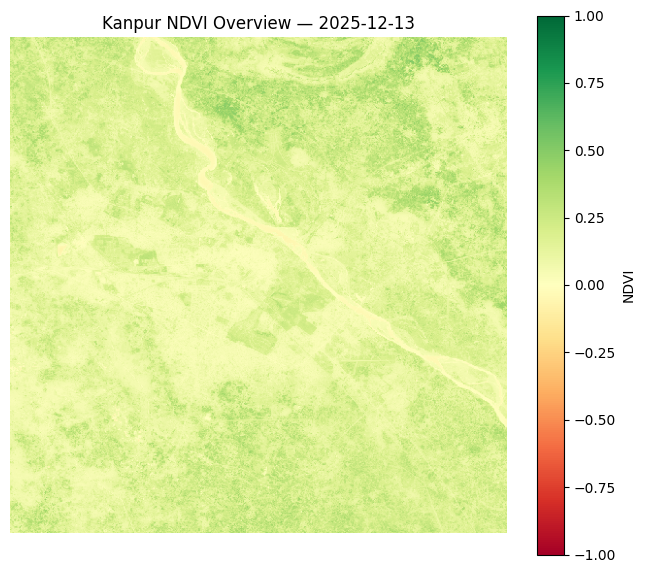

Overview shape: (512, 512)
Valid pixels: 262144
Mean NDVI: 0.15795363


In [4]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

item = items[1]
bbox = [80.2, 26.3, 80.5, 26.6]
output_size = 512

def read_small_crop(asset):
    with rasterio.open(asset.href) as src:
        # Convert Kanpur bounding box to the band's coordinate system
        bounds = transform_bounds(
            "EPSG:4326", src.crs, *bbox
        )

        window = from_bounds(*bounds, transform=src.transform)

        # Read a small overview instead of the entire raster
        data = src.read(
            1,
            window=window,
            out_shape=(output_size, output_size),
            masked=True
        )

        return data.astype("float32")

red = read_small_crop(item.assets["B04"])
nir = read_small_crop(item.assets["B08"])

red_data = red.filled(np.nan)
nir_data = nir.filled(np.nan)

valid = (
    ~np.ma.getmaskarray(red)
    & ~np.ma.getmaskarray(nir)
    & np.isfinite(red_data)
    & np.isfinite(nir_data)
    & (red_data > 0)
    & (nir_data > 0)
)

denominator = nir_data + red_data
ndvi = np.full(red_data.shape, np.nan, dtype="float32")

np.divide(
    nir_data - red_data,
    denominator,
    out=ndvi,
    where=valid & (denominator != 0)
)

plt.figure(figsize=(8, 7))
plt.imshow(
    np.ma.masked_invalid(ndvi),
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
plt.colorbar(label="NDVI")
plt.title(f"Kanpur NDVI Overview — {item.datetime.date()}")
plt.axis("off")
plt.show()

print("Overview shape:", ndvi.shape)
print("Valid pixels:", np.isfinite(ndvi).sum())
print("Mean NDVI:", np.nanmean(ndvi))

In [1]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

item = items[1]
bbox = [80.2, 26.3, 80.5, 26.6]
size = 512

def read_crop(asset):
    with rasterio.open(asset.href) as src:
        bounds = transform_bounds("EPSG:4326", src.crs, *bbox)
        window = from_bounds(*bounds, transform=src.transform)
        return src.read(
            window=window,
            out_shape=(3, size, size) if asset == item.assets["visual"] else (size, size),
            indexes=[1, 2, 3] if asset == item.assets["visual"] else 1,
            masked=True
        )

# Natural-colour image: RGB
rgb = read_crop(item.assets["visual"])
rgb = np.moveaxis(rgb, 0, -1).filled(0)

# NDVI bands
red_ma = read_crop(item.assets["B04"])
nir_ma = read_crop(item.assets["B08"])

red = red_ma.filled(np.nan).astype("float32")
nir = nir_ma.filled(np.nan).astype("float32")

valid = (
    ~np.ma.getmaskarray(red_ma)
    & ~np.ma.getmaskarray(nir_ma)
    & (red > 0) & (nir > 0)
)

ndvi = np.full(red.shape, np.nan, dtype="float32")
denom = red + nir

np.divide(nir - red, denom, out=ndvi,
          where=valid & (denom != 0))

fig, ax = plt.subplots(1, 2, figsize=(13, 6))

ax[0].imshow(rgb)
ax[0].set_title("Sentinel-2 Natural Colour")
ax[0].axis("off")

im = ax[1].imshow(
    np.ma.masked_invalid(ndvi),
    cmap="RdYlGn", vmin=-1, vmax=1
)
ax[1].set_title("NDVI Map")
ax[1].axis("off")

fig.colorbar(im, ax=ax[1], label="NDVI", shrink=0.75)
fig.suptitle(f"Kanpur Earth Observation — {item.datetime.date()}")
plt.tight_layout()
plt.show()

print("Mean NDVI:", np.nanmean(ndvi))

NameError: name 'items' is not defined

In [2]:
%pip install -q pystac-client planetary-computer rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.7 MB/s eta 0:00:00


In [3]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[80.2, 26.3, 80.5, 26.6],
    datetime="2025-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 10}},
    max_items=10
)

items = list(search.items())
item = items[1]

print("Scene restored:", item.id)
print("Date:", item.datetime.date())

Scene restored: S2B_MSIL2A_20251213T051119_R019_T44RMQ_20251213T070912
Date: 2025-12-13


Scene date: 2025-12-13
Cloud cover: 3.691129 %


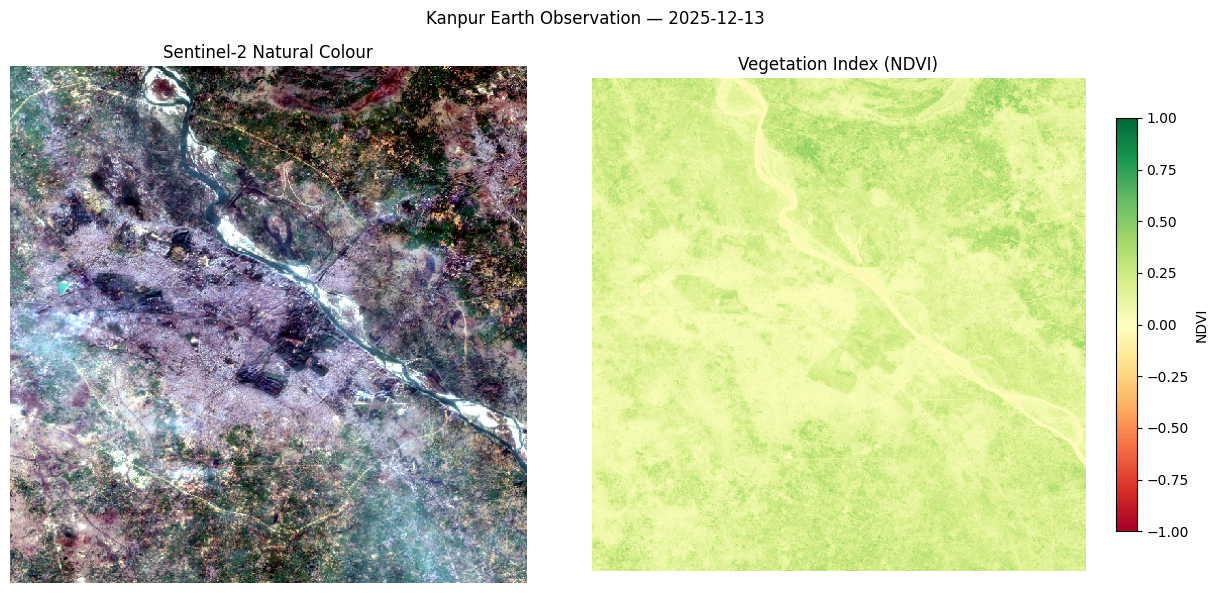


--- NDVI Statistics ---
Overview dimensions: (512, 512)
Valid pixels: 262144
Minimum NDVI: -0.0822
Maximum NDVI: 0.5441
Mean NDVI: 0.158


47

In [6]:
# ============================================================
# KANPUR SATELLITE IMAGE + NDVI
# Memory-safe 512 x 512 overview
# ============================================================

import gc
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

# ------------------------------------------------------------
# 1. Select scene and define study area
# ------------------------------------------------------------

item = items[1]

bbox = [80.2, 26.3, 80.5, 26.6]
size = 512

print("Scene date:", item.datetime.date())
print("Cloud cover:", item.properties.get("eo:cloud_cover"), "%")

# ------------------------------------------------------------
# 2. Read only a small crop of each band
# ------------------------------------------------------------

def read_crop(asset):
    with rasterio.open(asset.href) as src:

        bounds = transform_bounds(
            "EPSG:4326",
            src.crs,
            *bbox
        )

        window = from_bounds(
            *bounds,
            transform=src.transform
        )

        data = src.read(
            1,
            window=window,
            out_shape=(size, size),
            masked=True
        )

        return data.astype("float32")


# Sentinel-2 visible bands
blue_ma = read_crop(item.assets["B02"])
green_ma = read_crop(item.assets["B03"])
red_ma = read_crop(item.assets["B04"])

# Near-infrared band
nir_ma = read_crop(item.assets["B08"])

# ------------------------------------------------------------
# 3. Create natural-colour RGB image
# ------------------------------------------------------------

blue = blue_ma.filled(np.nan)
green = green_ma.filled(np.nan)
red = red_ma.filled(np.nan)

rgb = np.stack(
    [red, green, blue],
    axis=-1
).astype("float32")

rgb_valid = (
    np.isfinite(rgb).all(axis=2)
    & (rgb >= 0).all(axis=2)
)

rgb_display = np.zeros(
    (size, size, 3),
    dtype="float32"
)

# Contrast stretch each colour channel safely
for channel in range(3):

    band = rgb[:, :, channel]
    good = band[rgb_valid]

    if good.size > 0:
        low, high = np.percentile(good, [2, 98])

        if high > low:
            stretched = (
                np.nan_to_num(band, nan=low) - low
            ) / (high - low)

            rgb_display[:, :, channel] = np.clip(
                stretched, 0, 1
            )

# Show missing RGB pixels as black
rgb_display[~rgb_valid] = 0

# ------------------------------------------------------------
# 4. Calculate NDVI from Red and NIR
# ------------------------------------------------------------

red_data = red_ma.filled(np.nan)
nir_data = nir_ma.filled(np.nan)

valid = (
    ~np.ma.getmaskarray(red_ma)
    & ~np.ma.getmaskarray(nir_ma)
    & np.isfinite(red_data)
    & np.isfinite(nir_data)
    & (red_data > 0)
    & (nir_data > 0)
)

denominator = red_data + nir_data

ndvi = np.full(
    (size, size),
    np.nan,
    dtype="float32"
)

np.divide(
    nir_data - red_data,
    denominator,
    out=ndvi,
    where=valid & (denominator != 0)
)

# ------------------------------------------------------------
# 5. Plot RGB image and NDVI side by side
# ------------------------------------------------------------

fig, ax = plt.subplots(
    1, 2,
    figsize=(13, 6)
)

ax[0].imshow(rgb_display)
ax[0].set_title("Sentinel-2 Natural Colour")
ax[0].axis("off")

ndvi_plot = ax[1].imshow(
    np.ma.masked_invalid(ndvi),
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

ax[1].set_title("Vegetation Index (NDVI)")
ax[1].axis("off")

fig.colorbar(
    ndvi_plot,
    ax=ax[1],
    label="NDVI",
    shrink=0.8
)

fig.suptitle(
    f"Kanpur Earth Observation — {item.datetime.date()}"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Print statistics
# ------------------------------------------------------------

valid_ndvi = ndvi[np.isfinite(ndvi)]

print("\n--- NDVI Statistics ---")
print("Overview dimensions:", ndvi.shape)
print("Valid pixels:", len(valid_ndvi))

if len(valid_ndvi) > 0:
    print("Minimum NDVI:", round(float(np.min(valid_ndvi)), 4))
    print("Maximum NDVI:", round(float(np.max(valid_ndvi)), 4))
    print("Mean NDVI:", round(float(np.mean(valid_ndvi)), 4))
else:
    print("No valid NDVI pixels found.")

# Release temporary arrays
del blue_ma, green_ma, red_ma, nir_ma
gc.collect()

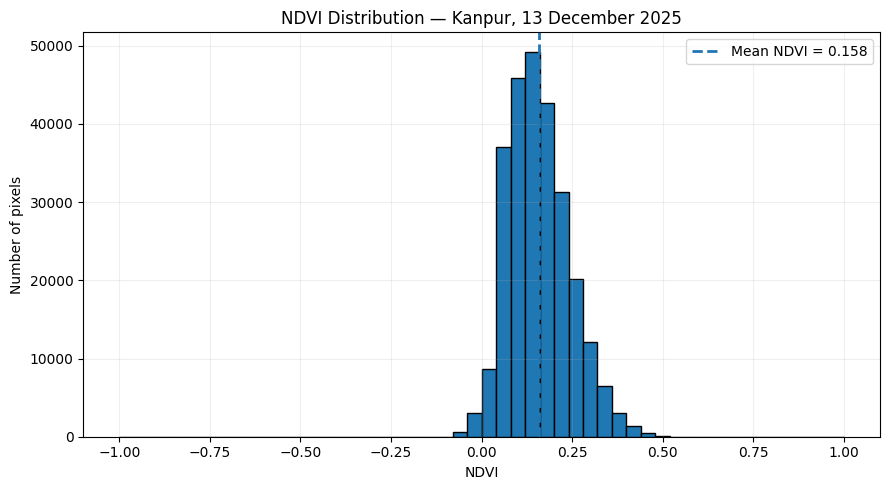

Valid pixels: 262144
Mean NDVI: 0.158
Median NDVI: 0.1488
Standard deviation: 0.0851


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Keep only valid NDVI values
valid_ndvi = ndvi[np.isfinite(ndvi)]

# Plot histogram
plt.figure(figsize=(9, 5))

plt.hist(
    valid_ndvi,
    bins=50,
    range=(-1, 1),
    edgecolor="black"
)

plt.axvline(
    np.mean(valid_ndvi),
    linestyle="--",
    linewidth=2,
    label=f"Mean NDVI = {np.mean(valid_ndvi):.3f}"
)

plt.xlabel("NDVI")
plt.ylabel("Number of pixels")
plt.title("NDVI Distribution — Kanpur, 13 December 2025")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Valid pixels:", len(valid_ndvi))
print("Mean NDVI:", round(float(np.mean(valid_ndvi)), 4))
print("Median NDVI:", round(float(np.median(valid_ndvi)), 4))
print("Standard deviation:", round(float(np.std(valid_ndvi)), 4))

NDVI range analysis
-------------------
Low / near-zero: 71,163 pixels (27.15%)
Low positive: 116,007 pixels (44.25%)
Moderate positive: 73,033 pixels (27.86%)
Higher positive: 1,941 pixels (0.74%)


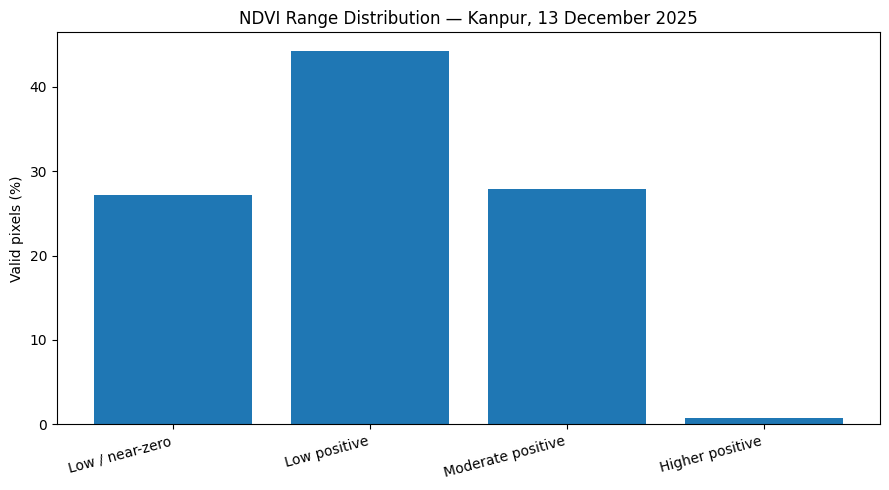

In [8]:
import numpy as np
import matplotlib.pyplot as plt

values = ndvi[np.isfinite(ndvi)]

# Approximate NDVI ranges for exploratory analysis
ranges = [
    ("Low / near-zero", -1.0, 0.1),
    ("Low positive", 0.1, 0.2),
    ("Moderate positive", 0.2, 0.4),
    ("Higher positive", 0.4, 1.0)
]

labels = []
percentages = []

print("NDVI range analysis")
print("-------------------")

for label, lower, upper in ranges:
    if upper == 1.0:
        count = np.sum((values >= lower) & (values <= upper))
    else:
        count = np.sum((values >= lower) & (values < upper))

    percentage = count / len(values) * 100
    labels.append(label)
    percentages.append(percentage)

    print(f"{label}: {count:,} pixels ({percentage:.2f}%)")

plt.figure(figsize=(9, 5))
plt.bar(labels, percentages)
plt.ylabel("Valid pixels (%)")
plt.title("NDVI Range Distribution — Kanpur, 13 December 2025")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

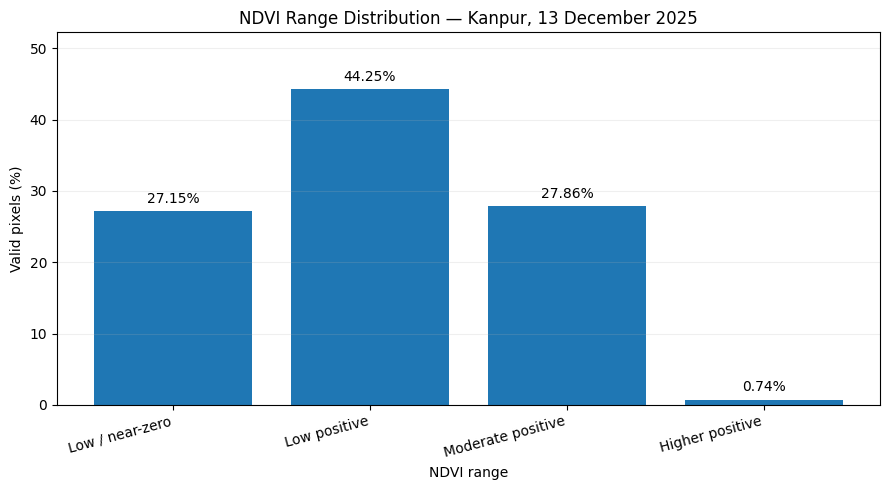

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, percentages)

plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.ylabel("Valid pixels (%)")
plt.xlabel("NDVI range")
plt.title("NDVI Range Distribution — Kanpur, 13 December 2025")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, max(percentages) + 8)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Results and Interpretation

The Sentinel-2 L2A scene acquired on 13 December 2025 was used to calculate the Normalized Difference Vegetation Index (NDVI) over the selected study area near Kanpur, India. The analysis was performed on a 512 × 512 pixel overview containing 262,144 valid pixels.

The mean NDVI was approximately 0.158, while the median was approximately 0.149. In the NDVI range analysis, 44.25% of pixels fell between 0.1 and 0.2, 27.86% fell between 0.2 and 0.4, and 0.74% fell between 0.4 and 1.0. The remaining 27.15% had NDVI values below 0.1.

These results show that low-positive NDVI values were the most common in the selected image. This provides an initial overview of the spatial distribution of vegetation-related spectral signals in the study area.

### Limitations

- The analysis uses a single acquisition date and does not represent seasonal or annual vegetation trends.
- NDVI values alone cannot reliably distinguish specific land-cover classes.
- The results describe the selected 512 × 512 pixel overview, not the entirety of Kanpur.
- NDVI can be affected by soil background, surface moisture, atmospheric conditions, and vegetation seasonality.

### Conclusion

This project demonstrates a basic satellite remote-sensing workflow using Sentinel-2 imagery, Python, Rasterio, and NumPy to calculate NDVI and summarize its distribution. Further work could include NDVI mapping, land-cover classification, and comparison of multiple dates to investigate seasonal changes in vegetation.

